<a href="https://colab.research.google.com/github/3b232100-yiren/2026_DL_hws/blob/main/hw4_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from sklearn.metrics import confusion_matrix
import seaborn as sns
import ipywidgets as widgets
from IPython.display import display

##資料預處理

In [ ]:
# 載入 CIFAR-10 資料集
(X_train_raw, y_train_raw), (X_test, y_test) = cifar10.load_data()

# 定義標籤名稱
class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1446s 8us/step


In [ ]:
# 2. 呈現訓練資料與測試資料的形狀
print("=== 資料形狀檢視 ===")
print("訓練資料圖片形狀 (X_train_raw):", X_train_raw.shape)
print("訓練資料標籤形狀 (y_train_raw):", y_train_raw.shape)
print("測試資料圖片形狀 (X_test):", X_test.shape)
print("測試資料標籤形狀 (y_test):", y_test.shape)
print("-" * 50)

=== 資料形狀檢視 ===
訓練資料圖片形狀 (X_train_raw): (50000, 32, 32, 3)
訓練資料標籤形狀 (y_train_raw): (50000, 1)
測試資料圖片形狀 (X_test): (10000, 32, 32, 3)
測試資料標籤形狀 (y_test): (10000, 1)
--------------------------------------------------


=== 顯示訓練資料樣本（三張） ===


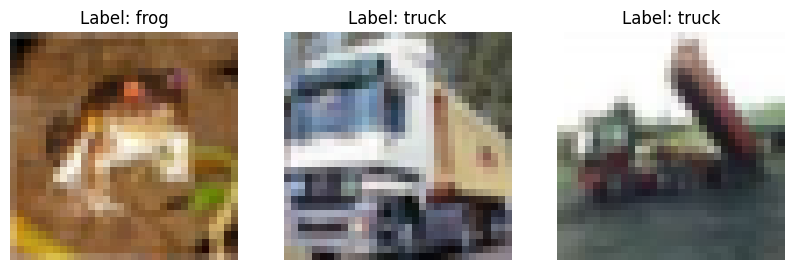

正規化與 One-hot Encoding 已完成


In [ ]:
# 3. 顯示至少三張訓練資料（圖片與真實標籤名稱，非數字）
print("=== 顯示訓練資料樣本（三張） ===")
plt.figure(figsize=(10, 3))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(X_train_raw[i])
    label_index = y_train_raw[i][0]
    plt.title(f"Label: {class_names[label_index]}")
    plt.axis('off')
plt.show()

# 4. 資料正規化 (0~255 縮放到 0~1) 與 One-hot Encoding
X_train = X_train_raw.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

y_train = to_categorical(y_train_raw, 10)
y_test_cat = to_categorical(y_test, 10)
print("正規化與 One-hot Encoding 已完成")

##建立神經網路模型

In [ ]:
model = Sequential([
    # 第 01 ~ 04 層
    Conv2D(32, (3, 3), padding='same', activation='relu', input_shape=(32, 32, 3)),
    Dropout(0.3),
    Conv2D(32, (3, 3), padding='same', activation='relu'),
    MaxPooling2D((2, 2)),

    # 第 05 ~ 08 層
    Conv2D(64, (3, 3), padding='same', activation='relu'),
    Dropout(0.3),
    Conv2D(64, (3, 3), padding='same', activation='relu'),
    MaxPooling2D((2, 2)),

    # 第 09 ~ 12 層
    Conv2D(128, (3, 3), padding='same', activation='relu'),
    Dropout(0.3),
    Conv2D(128, (3, 3), padding='same', activation='relu'),
    MaxPooling2D((2, 2)),

    # 第 13 ~ 19 層
    Flatten(),
    Dropout(0.3),
    Dense(2500, activation='relu'),
    Dropout(0.3),
    Dense(1500, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2500)           │     5,122,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 2500)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1500)           │     3,751,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 1500)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │        15,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,176,018 (35.00 MB)

 Trainable params: 9,176,018 (35.00 MB)

 Non-trainable params: 0 (0.00 B)

##訓練神經網路模型

In [ ]:
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(X_train, y_train,
                    epochs=50,
                    batch_size=128,
                    validation_split=0.2)

Epoch 1/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 48s 91ms/step - accuracy: 0.3237 - loss: 1.8042 - val_accuracy: 0.4522 - val_loss: 1.4858
Epoch 2/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.4971 - loss: 1.3717 - val_accuracy: 0.5657 - val_loss: 1.2368
Epoch 3/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.5835 - loss: 1.1549 - val_accuracy: 0.6212 - val_loss: 1.0795
Epoch 4/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.6342 - loss: 1.0184 - val_accuracy: 0.6841 - val_loss: 0.9152
Epoch 5/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.6707 - loss: 0.9308 - val_accuracy: 0.6976 - val_loss: 0.8659
Epoch 6/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.6977 - loss: 0.8519 - val_accuracy: 0.6965 - val_loss: 0.8668
Epoch 7/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.7232 - loss: 0.7871 - val_accuracy: 0.7306 - val_loss: 0.7644
Epoch 8/50
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.7397 - loss: 0.7371 - val_acc

##Loss & Accuracy折線圖

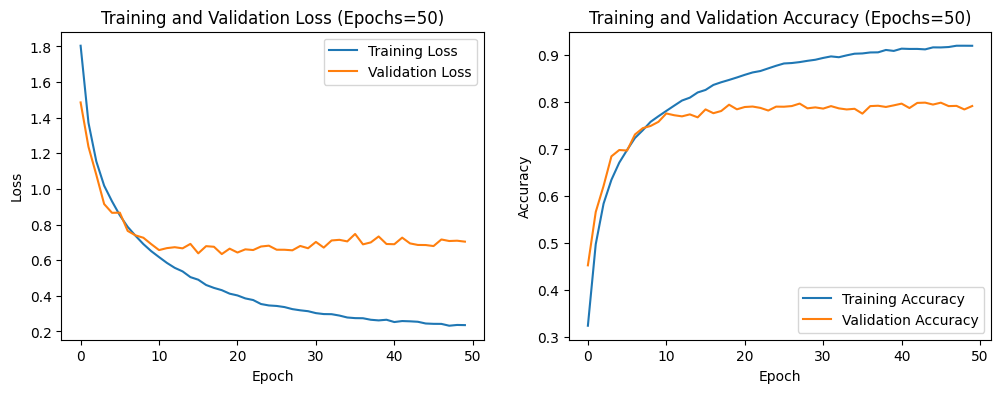

In [12]:
plt.figure(figsize=(12, 4))

# Loss 折線圖
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss (Epochs=50)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Accuracy 折線圖
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy (Epochs=50)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.show()

##評估模型準確率

313/313 - 1s - 3ms/step - accuracy: 0.7822 - loss: 0.7366

測試集準確率 (Test Accuracy): 78.22%
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


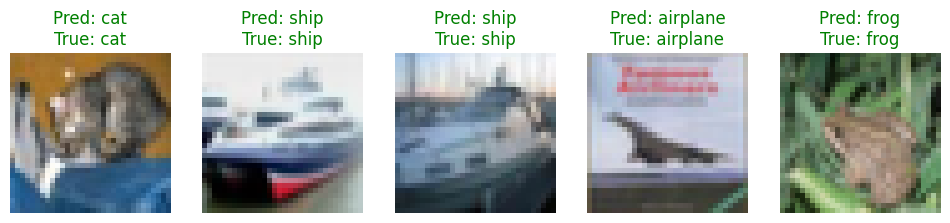

In [13]:
test_loss, test_acc = model.evaluate(X_test, y_test_cat, verbose=2)
print(f"\n測試集準確率 (Test Accuracy): {test_acc * 100:.2f}%")

predictions = model.predict(X_test)
predicted_classes = np.argmax(predictions, axis=1)

plt.figure(figsize=(12, 5))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_test[i])
    pred_label = class_names[predicted_classes[i]]
    true_label = class_names[y_test[i][0]]
    color = 'green' if pred_label == true_label else 'red'
    plt.title(f"Pred: {pred_label}\nTrue: {true_label}", color=color)
    plt.axis('off')
plt.show()

##混淆矩陣

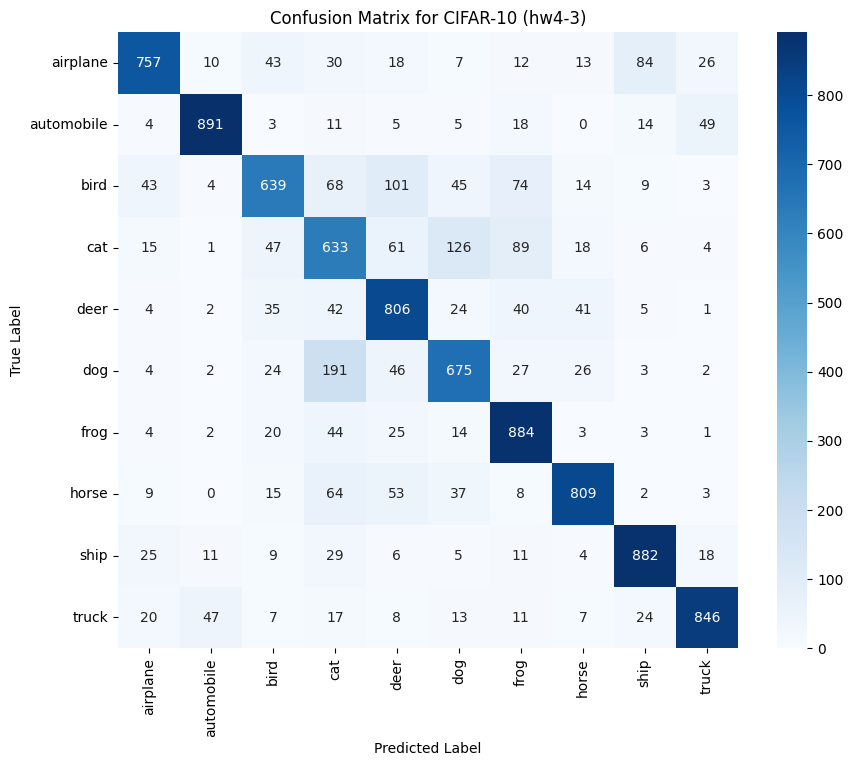

In [14]:
cm = confusion_matrix(y_test, predicted_classes)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for CIFAR-10 (hw4-3)')
plt.show()

##儲存完整模型

In [15]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [16]:
%cd '/content/drive/My Drive/Colab Notebooks'

/content/drive/My Drive/Colab Notebooks


In [17]:
model.save('my_cnn_model_hw4-3.keras')

##使用 interact_manual 呈現測試圖片的預測結果

In [18]:
def predict_test_image(index):
    plt.figure(figsize=(3, 3))
    plt.imshow(X_test[index])
    plt.axis('off')
    plt.show()

    pred_idx = predicted_classes[index]
    true_idx = y_test[index][0]

    print(f"測試圖片編號: {index}")
    print(f"預測結果名稱: {class_names[pred_idx]}")
    print(f"真實標籤名稱: {class_names[true_idx]}")
    if pred_idx == true_idx:
        print("預測正確！")
    else:
        print("預測錯誤！")

widgets.interact_manual(predict_test_image, index=widgets.IntSlider(min=0, max=9999, step=1, value=0));


interactive(children=(IntSlider(value=0, description='index', max=9999), Button(description='Run Interact', st…